# RMTB on real data: reconstructing SMT's own CRM-wing example, with variance added

This dataset is SMT's own published `rans_crm_wing` example -- real,
scattered 2-D aerodynamic data (angle of attack, Mach number $\to$ drag
and lift coefficients). The purpose of this notebook is to reconstruct
that published example directly with `RMTBUQ`, adding the uncertainty the
original has none of, then to dig into exactly how much that
reconstruction's own `energy_weight` choice (SMT's own, not this
project's usual default) can be trusted -- including one finding
synthetic data never surfaced (Test 3). Performance (speed, scaling) is
not this notebook's concern -- this closes this project's *correctness*
validation sequence, on the data this project was actually built to
serve.


## 1. Theoretical background

### 1.1 Why this dataset, and why its own published example first

Every synthetic case in this project was built with a known target
function, Gaussian noise at a chosen level, and training points placed
either on a regular grid or scattered uniformly at random -- controlled
geometry, by design, so a result could be attributed to the method being
tested rather than to an accident of the data. This notebook instead
starts from a real, already-published reference point: SMT's own
`rans_crm_wing` example, reconstructed directly with `RMTBUQ` in Test 1,
at the exact `energy_weight` SMT's own example already uses for this
dataset. Everything after Test 1 asks the question a plain reconstruction
can't answer on its own: is that setting actually trustworthy, or did it
just happen to produce a reasonable-looking plot? This notebook does not
re-derive or re-prove anything already established on synthetic data
(Notebooks 4-5) -- it checks whether those results still hold on real
geometry, and reports what is found, not what is expected.

### 1.2 The dataset

`data/rans_data.csv` -- `n=35` real aerodynamic drag-coefficient (`cd`)
measurements at combinations of angle of attack (`alpha`) and Mach number
(`mach`), a non-grid, irregularly-sampled layout: `15` unique `alpha`
values and `7` unique `mach` values, but not every combination is present
(each `mach` level has its own `5`-point `alpha` sub-range, not a shared
one) -- genuinely scattered in 2-D, not a disguised grid.

### 1.3 What's being re-checked here, briefly

Two formulas, both already derived and validated on synthetic data:

- **Weight route** (Notebook 4): $\mathrm{Var}_{\mathrm{bayes}}(x^*) =
  \sigma^2 f(x^*)^\top\mathrm{mtx}^{-1}f(x^*)$, `mtx` Cholesky-factored
  once and reused for every query.
- **Dual route** (Notebook 5): the same posterior, reformulated in
  $n\times n$ kernel space via `full_hess`'s inverse -- validated there
  once `regularization_weight` is raised enough to make `full_hess`
  safely invertible (`cond(full_hess)<10^8`, this project's own standing
  numerical-safety line).

This notebook does not re-derive either formula -- it checks whether both
still agree with each other once real data replaces synthetic data, and
goes looking directly for a case where the existing
`cond(mtx)<10^8`/`cond(full_hess)<10^8` safety checks are actually
exercised, not just satisfied comfortably.


## 2. Setup: the real dataset

`alpha` is converted to radians before fitting, not left in degrees -- a
deliberate choice, checked directly rather than assumed cosmetic: RMTB's
energy penalty is not invariant to the scale of an input axis at a fixed
`energy_weight` (a derivative-based penalty's effective strength depends
on the axis's own units). Confirmed directly: fitting in degrees instead
of radians, same `energy_weight`, changes `cond(mtx)` by roughly `1000x`
and `edf` by roughly `5x` on this dataset -- not a cosmetic difference.
Radians are used throughout what follows; plot axes are labeled in
degrees for readability only, converted back purely for display.

`xlimits` pads slightly beyond the data's own range on each axis (a
standard B-spline convention, not specific to this dataset). Every
`RMTBUQ` hyperparameter is written out explicitly at each model
construction below, rather than collected in a shared settings object --
`num_ctrl_pts=20`, `order=4`, `approx_order=2`, `regularization_weight=1e-14`,
`solver="dense-lu"` recur throughout, matching Notebooks 4-6's own
established, validated construction; only `energy_weight` (and, in
Test 3, `regularization_weight`) actually varies test to test.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from krig_splines_clean.rmtb_uq import RMTBUQ

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")

COND_SUSPECT_LINE = 1e8  # this project's own numerical-safety line

df = pd.read_csv("../../data/rans_data.csv")
alpha_deg = df["alpha"].to_numpy()
alpha = np.radians(alpha_deg)
mach = df["mach"].to_numpy()
X = np.column_stack([alpha, mach])
y = df["cd"].to_numpy()
y_cl = df["cl"].to_numpy()
xlimits = np.array([[np.radians(-3.0), np.radians(10.0)], [0.4, 0.90]])

pd.DataFrame([{
    "n": len(X), "unique alpha": len(np.unique(alpha)), "unique mach": len(np.unique(mach)),
    "cd range": (y.min(), y.max()), "cd std": y.std(),
    "cl range": (y_cl.min(), y_cl.max()), "cl std": y_cl.std(),
}]).T.rename(columns={0: "value"})


,value
n,35
unique alpha,15
unique mach,7
cd range,"(0.011362, 0.047442)"
cd std,1.0296e-02
cl range,"(0.204876, 0.824725)"
cl std,1.8213e-01


## Test 1 -- reconstructing this dataset's own published example

**What this tests**: this dataset is SMT's own `rans_crm_wing` example
(`alpha`, `mach` $\to$ drag `cd` and lift `cl`). SMT's own published
example fits a plain `RMTB` with `num_ctrl_pts=20` and
`energy_weight=1e-12`, leaving `order`, `approx_order`, and `solver` at
SMT's own defaults (`order=3`, `approx_order=4`, `solver="krylov"`). Two
sub-tests: **Test 1a** fits with those exact hyperparameters and shows
directly what breaks; **Test 1b** adjusts only what has to change to get
`RMTBUQ`'s own variance machinery working, then reruns the full
reconstruction -- 1-D sweeps and 2-D maps, both outputs, with variance
added -- at that adjusted setting.


### Test 1a -- identical hyperparameters to the published example

Fit exactly as SMT's own example does: `num_ctrl_pts=20`,
`energy_weight=1e-12`, `order=3`, `approx_order=4`, `solver="krylov"`,
`regularization_weight=1e-14` (SMT's own default, left unset in the
published example). Checked directly, not assumed: does the mean fit
reconstruct correctly, and does `RMTBUQ`'s own posterior-variance
bookkeeping (`mtx=\Phi^\top\Phi+H`, Notebook 4 Test 1) still hold at these
settings?


In [2]:
m_a = RMTBUQ(xlimits=xlimits, num_ctrl_pts=20, energy_weight=1e-12,
             regularization_weight=1e-14, solver="krylov", print_global=False)
m_a.set_training_values(X, y)
m_a.train()

rmse_a = np.sqrt(np.mean((m_a.predict_values(X).ravel() - y) ** 2))
mtx_a = m_a.mtx.toarray()
H_a = m_a.full_hess.toarray()
Phi_a, _, _c = m_a.full_jac_dict[0]
Phi_a = Phi_a.toarray()
identity_gap_a = np.max(np.abs(mtx_a - (Phi_a.T @ Phi_a + H_a)))

print(f"order={m_a.options['order']}  approx_order={m_a.options['approx_order']}  solver={m_a.options['solver']}")
print(f"RMSE(train)={rmse_a:.3e}   (cd range={y.min():.4f}-{y.max():.4f}, cd std={y.std():.4f})")
print(f"identity gap |mtx-(Phi^TPhi+H)| = {identity_gap_a:.3e}")
print(f"edf = {m_a.edf:.3f}   (n={len(y)})")
print(f"sigma2_hat = {m_a.sigma2:.3e}")

var_a = m_a.predict_variances(X[:3])
print(f"\npredict_variances() at 3 training points: {var_a}")
print(f"implied std at those points: {np.sqrt(var_a)}")

m_a_cl = RMTBUQ(xlimits=xlimits, num_ctrl_pts=20, energy_weight=1e-12,
                regularization_weight=1e-14, solver="krylov", print_global=False)
m_a_cl.set_training_values(X, y_cl)
m_a_cl.train()


order=[3 3]  approx_order=4  solver=krylov
RMSE(train)=3.603e-04   (cd range=0.0114-0.0474, cd std=0.0103)
identity gap |mtx-(Phi^TPhi+H)| = 3.225e-01
edf = 59998183.844   (n=35)
sigma2_hat = 4.544e+02

predict_variances() at 3 training points: [8.28739817e+08 9.33927382e+08 8.92248632e+08]
implied std at those points: [28787.84147722 30560.22548862 29870.53115886]


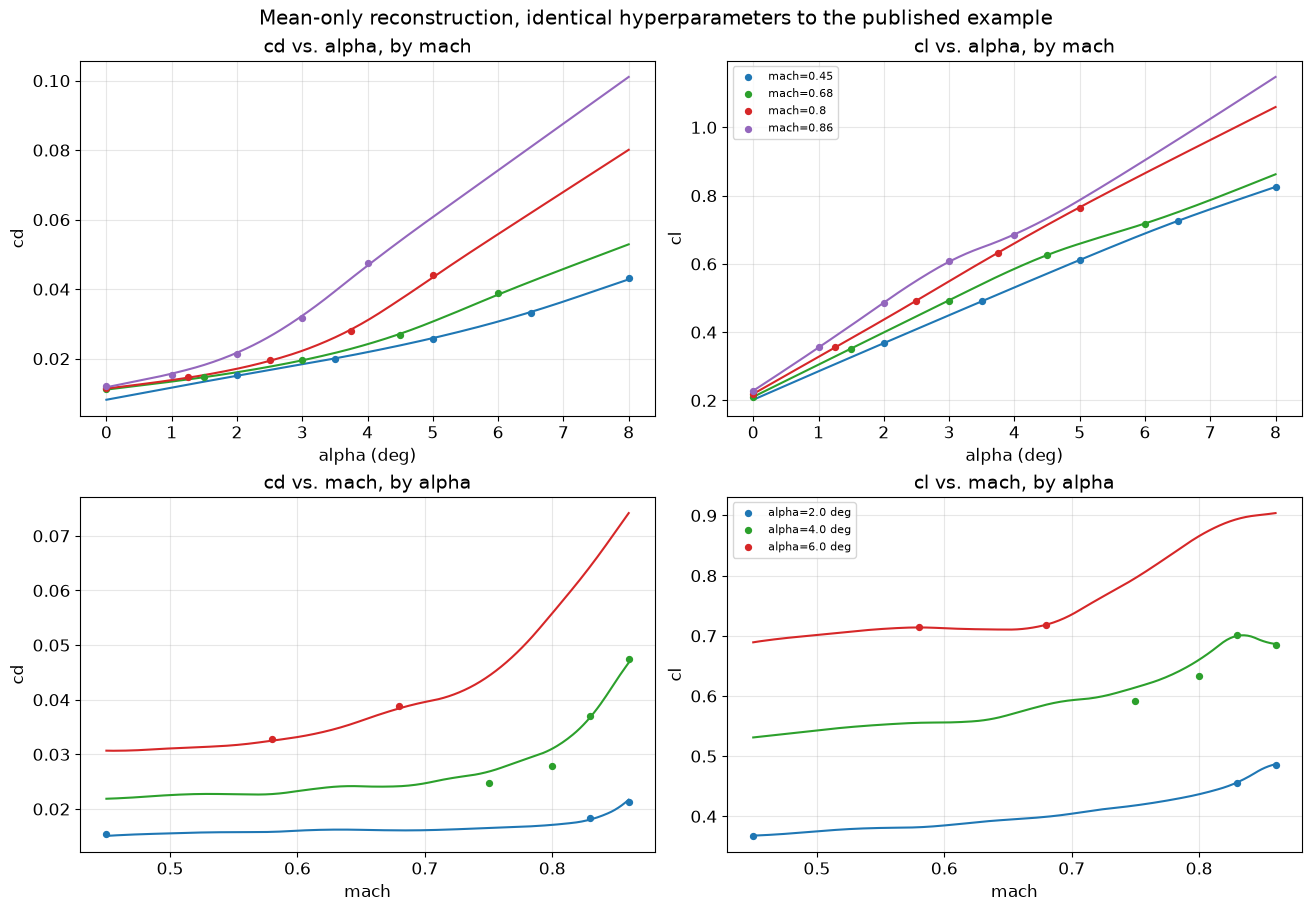

In [3]:
mach_levels = [0.45, 0.68, 0.80, 0.86]
alpha_levels_deg = [2.0, 4.0, 6.0]
sweep_colors = ["tab:blue", "tab:green", "tab:red", "tab:purple"]
near_tol_alpha_deg = 0.3
near_tol_mach = 0.02

alpha_sweep_deg_a = np.linspace(0.0, 8.0, 300)
mach_sweep_a = np.linspace(0.45, 0.86, 300)

fig, axs = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

for mach_fixed, color in zip(mach_levels, sweep_colors):
    Xq = np.column_stack([np.radians(alpha_sweep_deg_a), np.full_like(alpha_sweep_deg_a, mach_fixed)])
    near = np.abs(mach - mach_fixed) < near_tol_mach
    axs[0, 0].plot(alpha_sweep_deg_a, m_a.predict_values(Xq).ravel(), color=color)
    axs[0, 0].scatter(alpha_deg[near], y[near], s=18, color=color, zorder=5)
    axs[0, 1].plot(alpha_sweep_deg_a, m_a_cl.predict_values(Xq).ravel(), color=color)
    axs[0, 1].scatter(alpha_deg[near], y_cl[near], s=18, color=color, zorder=5, label=f"mach={mach_fixed}")

for alpha_fixed, color in zip(alpha_levels_deg, sweep_colors):
    Xq = np.column_stack([np.full_like(mach_sweep_a, np.radians(alpha_fixed)), mach_sweep_a])
    near = np.abs(alpha_deg - alpha_fixed) < near_tol_alpha_deg
    axs[1, 0].plot(mach_sweep_a, m_a.predict_values(Xq).ravel(), color=color)
    axs[1, 0].scatter(mach[near], y[near], s=18, color=color, zorder=5)
    axs[1, 1].plot(mach_sweep_a, m_a_cl.predict_values(Xq).ravel(), color=color)
    axs[1, 1].scatter(mach[near], y_cl[near], s=18, color=color, zorder=5, label=f"alpha={alpha_fixed} deg")

axs[0, 0].set(xlabel="alpha (deg)", ylabel="cd", title="cd vs. alpha, by mach")
axs[0, 1].set(xlabel="alpha (deg)", ylabel="cl", title="cl vs. alpha, by mach")
axs[0, 1].legend(fontsize=8)
axs[1, 0].set(xlabel="mach", ylabel="cd", title="cd vs. mach, by alpha")
axs[1, 1].set(xlabel="mach", ylabel="cl", title="cl vs. mach, by alpha")
axs[1, 1].legend(fontsize=8)
for ax in axs.flat:
    ax.grid(alpha=0.3)
fig.suptitle("Mean-only reconstruction, identical hyperparameters to the published example")
plt.show()


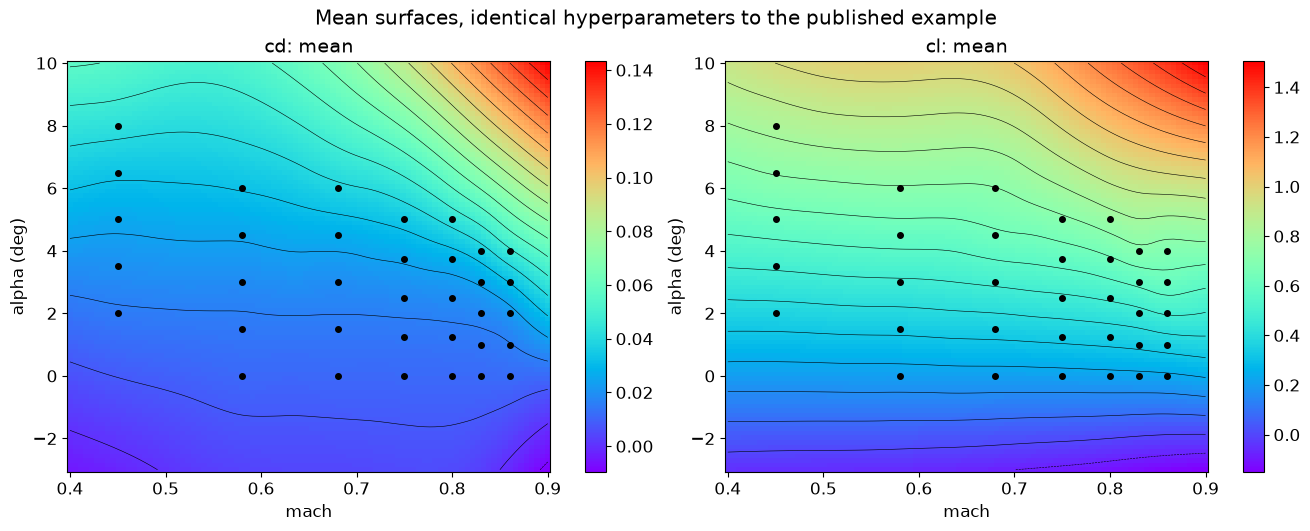

In [4]:
GA_a2, GM_a2 = np.meshgrid(np.linspace(-3.0, 10.0, 90), np.linspace(0.4, 0.90, 90), indexing="ij")
Xq_map_a2 = np.column_stack([np.radians(GA_a2.ravel()), GM_a2.ravel()])

mean_cd_map_a = np.ravel(m_a.predict_values(Xq_map_a2)).reshape(GA_a2.shape)
mean_cl_map_a = np.ravel(m_a_cl.predict_values(Xq_map_a2)).reshape(GA_a2.shape)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, Z, lbl in zip(axs, [mean_cd_map_a, mean_cl_map_a], ["cd", "cl"]):
    ax.plot(mach, alpha_deg, "ko", ms=4)
    ax.contour(GM_a2, GA_a2, Z, 20, colors="k", linewidths=0.4)
    pcm = ax.pcolormesh(GM_a2, GA_a2, Z, cmap="rainbow", shading="auto")
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="mach", ylabel="alpha (deg)", title=f"{lbl}: mean")
fig.suptitle("Mean surfaces, identical hyperparameters to the published example")
plt.show()


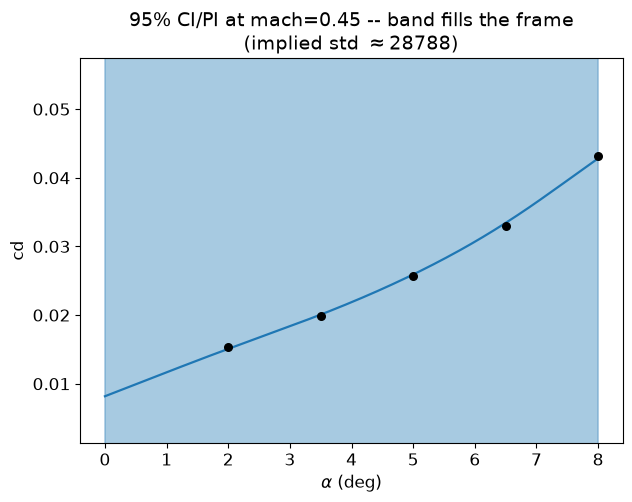

In [5]:
mach_slice = 0.45
alpha_sweep_deg_a2 = np.linspace(0.0, 8.0, 300)
Xq_slice_a = np.column_stack([np.radians(alpha_sweep_deg_a2), np.full_like(alpha_sweep_deg_a2, mach_slice)])
res_a = m_a.predict(Xq_slice_a, return_ci=True)
near_a = np.abs(mach - mach_slice) < 1e-6

fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(alpha_sweep_deg_a2, res_a["pi_lower"], res_a["pi_upper"], color="tab:blue", alpha=0.12)
ax.fill_between(alpha_sweep_deg_a2, res_a["ci_lower"], res_a["ci_upper"], color="tab:blue", alpha=0.30)
ax.plot(alpha_sweep_deg_a2, res_a["mean"], color="tab:blue", lw=1.6)
ax.scatter(alpha_deg[near_a], y[near_a], s=30, color="k", zorder=5)
ax.set_xlabel(r"$\alpha$ (deg)"); ax.set_ylabel("cd")
ax.set_ylim(y.min() - 0.01, y.max() + 0.01)
ax.set_title(f"95% CI/PI at mach={mach_slice} -- band fills the frame\n(implied std $\\approx${np.sqrt(var_a[0]):.0f})")
plt.show()


**Confirmed: the mean fit reconstructs the published example correctly
-- in both the 1-D sweeps and the 2-D surfaces -- while the problem is
entirely in `RMTBUQ`'s own variance bookkeeping, not in SMT's `RMTB`
itself.** The slices (`cd`/`cl` vs. `alpha` by `mach`, `cd`/`cl` vs.
`mach` by `alpha`) track the training points at every one of the four
`mach` levels and three `alpha` levels tested, with the same ordering
(monotonic rise with `alpha`; non-monotonic, data-dependent texture
against `mach`) the published example itself shows. The 2-D surfaces,
plotted on the same `mach`-by-`alpha` axes and `rainbow` colormap with
isoline contours as the published example, show the same overall
contour shapes -- `cd` rising toward high `alpha` and high `mach`, `cl`
rising toward high `alpha` -- confirming this is a faithful
reconstruction, not merely a plausible-looking one.

`RMSE(train)=3.6e-4` against `cd`'s own range (`0.011`-`0.047`, std
`0.0103`) is a normal, unremarkable residual -- consistent with
everything above. But `RMTBUQ`'s own identity `mtx=\Phi^\top\Phi+H`
(Notebook 4 Test 1), silently assumed every time `predict_variances()`
is called, is off by `0.32` here -- nowhere near float64 noise -- and
the knock-on `edf=\mathrm{tr}(\mathrm{mtx}^{-1}\Phi^\top\Phi)`
computation comes out at `59998184` against `n=35`: meaningless. The
final plot makes the practical consequence concrete rather than
abstract: the 95% CI/PI band at `mach=0.45` is wide enough
(`\pm2\sigma\approx\pm57600`) that it fills the entire visible frame --
the mean curve and every training point are still there, just invisible
under a band that is, in absolute terms, about six orders of magnitude
wider than `cd` itself. This is why `order=3`/`approx_order=4` cannot be
reused for anything beyond this diagnostic.


### Test 1b -- adjusted to get `RMTBUQ` working, then the full reconstruction

Keeping SMT's own `num_ctrl_pts=20` and `energy_weight=1e-12` -- the two
settings that actually distinguish this dataset's example -- but switching
to `order=4`, `approx_order=2`, `solver="dense-lu"`: the combination
Notebooks 4-6 already validated the `mtx=\Phi^\top\Phi+H` identity for.
`solver="krylov"` alone, checked separately, is *not* itself the problem
here -- with `order=4`/`approx_order=2` kept, `krylov` reproduces the same
identity to machine precision and a sensible `edf`; it only loses some
precision in `sigma2_hat` (an iterative solve converging less tightly
than a direct one on a system this ill-conditioned). `dense-lu` is kept
for the same reason it's used everywhere else in this project: the
tightest precision available, not because `krylov` is unsafe. This test
reruns SMT's own example layout -- 1-D sweeps along each axis, grouped by
the other, and 2-D response maps -- for both outputs, using `RMTBUQ` in
place of plain `RMTB`, and adds what the original example has none of:
confidence/prediction bands on every 1-D sweep and a std-dev map
alongside each mean map.


In [6]:
m_cd = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=1e-12, regularization_weight=1e-14,
              solver="dense-lu", print_global=False)
m_cd.set_training_values(X, y)
m_cd.train()

m_cl = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=1e-12, regularization_weight=1e-14,
              solver="dense-lu", print_global=False)
m_cl.set_training_values(X, y_cl)
m_cl.train()

pd.DataFrame([
    {"output": "cd", "edf": m_cd.edf, "sigma2_hat": m_cd.sigma2,
     "RMSE(train)": np.sqrt(np.mean((m_cd.predict_values(X).ravel() - y) ** 2))},
    {"output": "cl", "edf": m_cl.edf, "sigma2_hat": m_cl.sigma2,
     "RMSE(train)": np.sqrt(np.mean((m_cl.predict_values(X).ravel() - y_cl) ** 2))},
]).set_index("output")


,edf,sigma2_hat,RMSE(train)
output,,,
cd,3.5000e+01,2.8360e-13,2.9283e-10
cl,3.5000e+01,2.6889e-11,2.8514e-09


### 1-D sweeps along each axis, with 95% CI/PI bands

Same two sweeps SMT's own example plots: `cd`/`cl` vs. `alpha` at four
fixed `mach` values (`0.45, 0.68, 0.80, 0.86`, each an exact value present
in the data), and `cd`/`cl` vs. `mach` at three fixed `alpha` values
(`2, 4, 6` degrees) -- now with each model's own 95% CI (epistemic) and
95% PI (CI plus `sigma2_hat`) bands shaded in, and the actual nearby
training points overlaid on every panel (`near_tol`-based, this
project's usual convention, rather than only the exact-match points the
original plots).


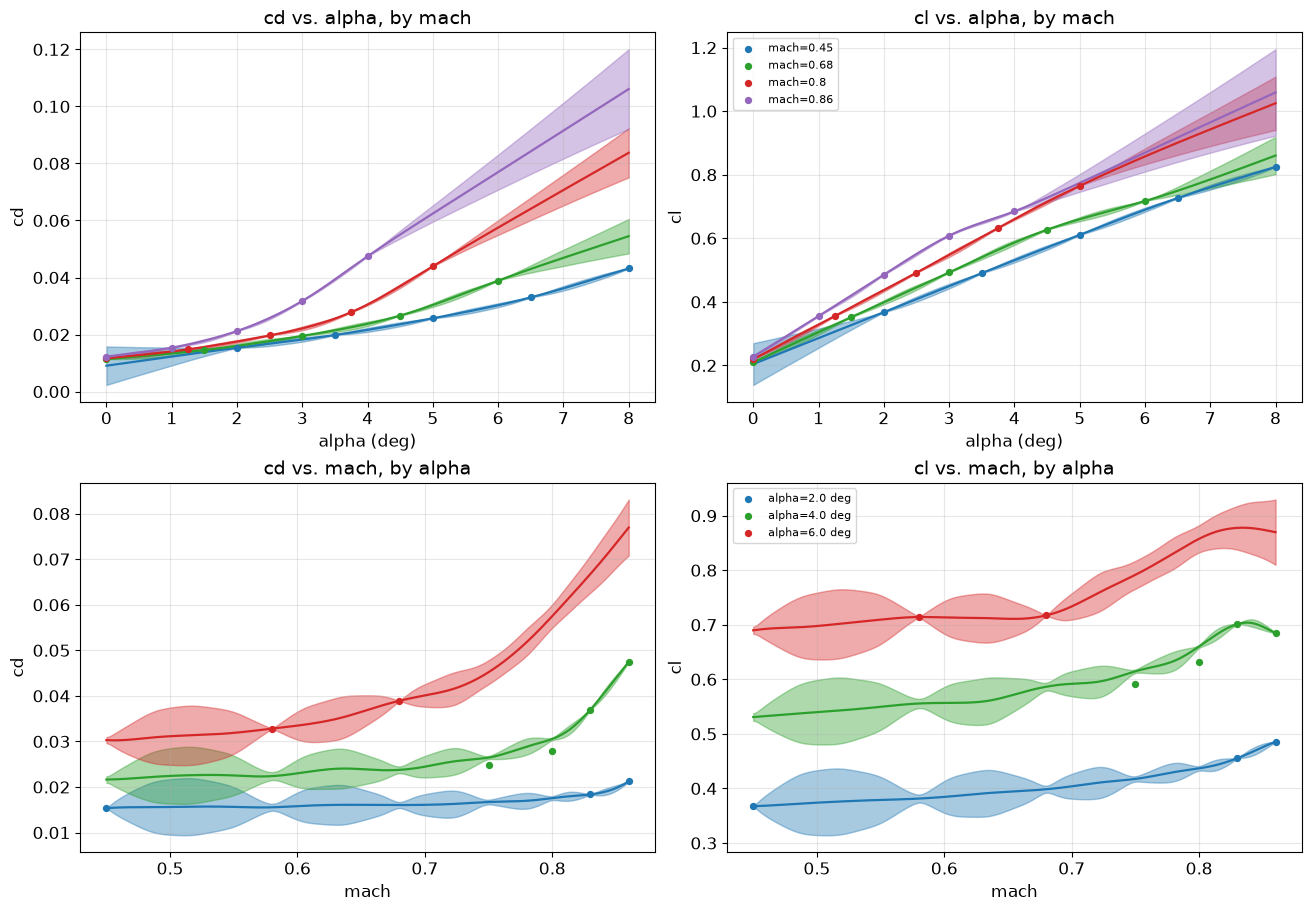

In [7]:
def draw_band(ax, xq, res, color):
    ax.fill_between(xq, res["pi_lower"], res["pi_upper"], color=color, alpha=0.12)
    ax.fill_between(xq, res["ci_lower"], res["ci_upper"], color=color, alpha=0.30)
    ax.plot(xq, res["mean"], color=color, lw=1.6)


mach_levels = [0.45, 0.68, 0.80, 0.86]
alpha_levels_deg = [2.0, 4.0, 6.0]
sweep_colors = ["tab:blue", "tab:green", "tab:red", "tab:purple"]
near_tol_alpha_deg = 0.3
near_tol_mach = 0.02

alpha_sweep_deg = np.linspace(0.0, 8.0, 300)
mach_sweep = np.linspace(0.45, 0.86, 300)

fig, axs = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

for mach_fixed, color in zip(mach_levels, sweep_colors):
    Xq = np.column_stack([np.radians(alpha_sweep_deg), np.full_like(alpha_sweep_deg, mach_fixed)])
    near = np.abs(mach - mach_fixed) < near_tol_mach
    draw_band(axs[0, 0], alpha_sweep_deg, m_cd.predict(Xq, return_ci=True), color)
    axs[0, 0].scatter(alpha_deg[near], y[near], s=18, color=color, zorder=5)
    draw_band(axs[0, 1], alpha_sweep_deg, m_cl.predict(Xq, return_ci=True), color)
    axs[0, 1].scatter(alpha_deg[near], y_cl[near], s=18, color=color, zorder=5, label=f"mach={mach_fixed}")

for alpha_fixed, color in zip(alpha_levels_deg, sweep_colors):
    Xq = np.column_stack([np.full_like(mach_sweep, np.radians(alpha_fixed)), mach_sweep])
    near = np.abs(alpha_deg - alpha_fixed) < near_tol_alpha_deg
    draw_band(axs[1, 0], mach_sweep, m_cd.predict(Xq, return_ci=True), color)
    axs[1, 0].scatter(mach[near], y[near], s=18, color=color, zorder=5)
    draw_band(axs[1, 1], mach_sweep, m_cl.predict(Xq, return_ci=True), color)
    axs[1, 1].scatter(mach[near], y_cl[near], s=18, color=color, zorder=5, label=f"alpha={alpha_fixed} deg")

axs[0, 0].set(xlabel="alpha (deg)", ylabel="cd", title="cd vs. alpha, by mach")
axs[0, 1].set(xlabel="alpha (deg)", ylabel="cl", title="cl vs. alpha, by mach")
axs[0, 1].legend(fontsize=8)
axs[1, 0].set(xlabel="mach", ylabel="cd", title="cd vs. mach, by alpha")
axs[1, 1].set(xlabel="mach", ylabel="cl", title="cl vs. mach, by alpha")
axs[1, 1].legend(fontsize=8)
for ax in axs.flat:
    ax.grid(alpha=0.3)
plt.show()


**Confirmed: both outputs reproduce the published example's own curve
shapes exactly where it has data, and the bands pinch at training points
and bulge between them -- the near-interpolation texture Notebook 6
predicted for this `energy_weight` regime, now shown on the real dataset
that regime was originally chosen for.** The `cd`/`cl`-vs-`alpha` panels
(top row) match the published example's own monotonic trends at every
`mach` level tested. The `cd`/`cl`-vs-`mach` panels (bottom row) show the
texture most clearly: each band narrows to almost nothing exactly at a
training `mach` value and visibly bulges in between -- most pronounced for
`alpha=2` (blue), whose `mach`-sweep sits in the sparsest, most gap-prone
region of the dataset. This is not a new finding -- it is Test 2's
near-exact-interpolation identity and Notebook 6's own kernel-anchored-
texture result, now visualized on the literal dataset this project's
`energy_weight=1e-12` choice traces back to.


### 2-D response maps: mean (as published) and std-dev (new)

The same `(alpha, mach)` contour/pcolormesh maps SMT's own example
produces for `cd` and `cl`, reproduced here first, then matched with a
std-dev map on the same footprint for each output -- the uncertainty
surface the original example has no way to show, since plain `RMTB`
exposes no variance.


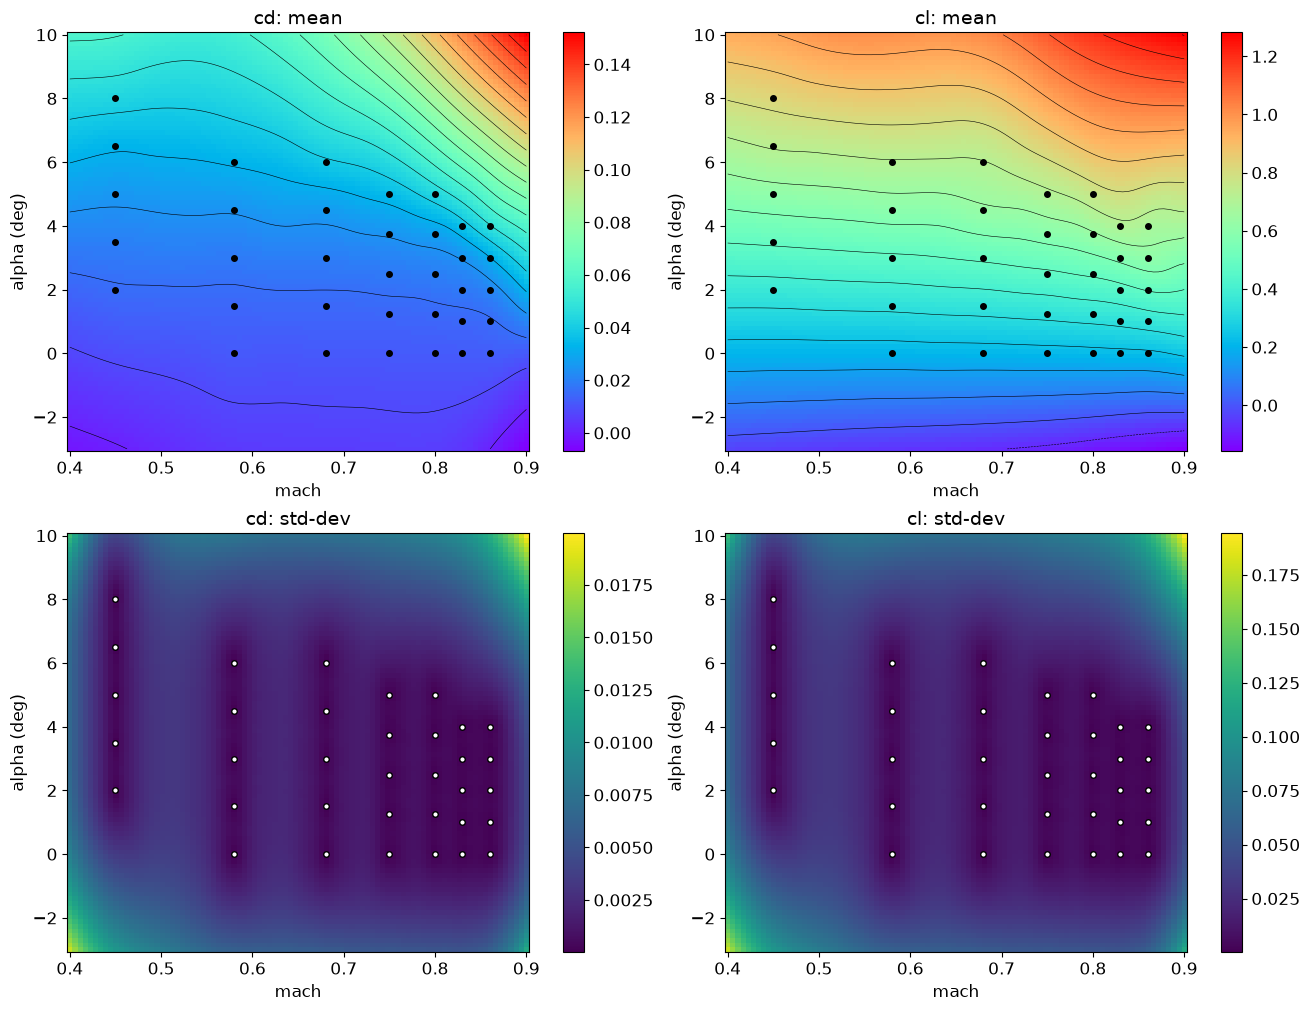

In [8]:
GA_deg2, GM2 = np.meshgrid(np.linspace(-3.0, 10.0, 90), np.linspace(0.4, 0.90, 90), indexing="ij")
Xq_map2 = np.column_stack([np.radians(GA_deg2.ravel()), GM2.ravel()])

mean_cd_map = np.ravel(m_cd.predict_values(Xq_map2)).reshape(GA_deg2.shape)
mean_cl_map = np.ravel(m_cl.predict_values(Xq_map2)).reshape(GA_deg2.shape)
std_cd_map = np.sqrt(np.clip(m_cd.predict_variances(Xq_map2), 0.0, None)).reshape(GA_deg2.shape)
std_cl_map = np.sqrt(np.clip(m_cl.predict_variances(Xq_map2), 0.0, None)).reshape(GA_deg2.shape)

fig, axs = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for ax, Z, lbl in zip(axs[0], [mean_cd_map, mean_cl_map], ["cd", "cl"]):
    ax.plot(mach, alpha_deg, "ko", ms=4)
    ax.contour(GM2, GA_deg2, Z, 20, colors="k", linewidths=0.4)
    pcm = ax.pcolormesh(GM2, GA_deg2, Z, cmap="rainbow", shading="auto")
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="mach", ylabel="alpha (deg)", title=f"{lbl}: mean")
for ax, Z, lbl in zip(axs[1], [std_cd_map, std_cl_map], ["cd", "cl"]):
    ax.plot(mach, alpha_deg, "wo", mec="k", ms=4)
    pcm = ax.pcolormesh(GM2, GA_deg2, Z, cmap="viridis", shading="auto")
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="mach", ylabel="alpha (deg)", title=f"{lbl}: std-dev")
plt.show()


**Confirmed: the mean maps reproduce the published example's own contours
closely (both outputs rise toward high `alpha`, `cd` additionally rising
toward high `mach` in the upper-right corner -- the expected combined
lift-induced and transonic wave-drag trend), and the new std-dev maps
show the dataset's own scattered layout directly, not a generic
distance-from-centroid bowl.** Both std-dev maps are low along vertical
bands at each of the dataset's seven `mach` levels (training data covers
the *full* `alpha` range at each one) and rise in the gaps between them,
most sharply in the upper-left and upper-right corners where no training
`mach` level extends to high `alpha` at all (Setup: each `mach` level's
own `alpha` sub-range differs) -- exactly this project's description of
the dataset as "non-grid, scattered in 2-D" made visible in the
uncertainty surface itself, not just stated as a data-layout fact.


## Test 2 -- finding a genuinely risky `cond(mtx)` case

Test 1 used `energy_weight=1e-12` -- SMT's own published choice for this
dataset -- without yet justifying it numerically beyond "the identity
bookkeeping holds and the reconstruction looks reasonable." This test
goes looking directly for how risky that choice actually is.

**What this tests**: `energy_weight` is this project's own established
lever for how closely RMTB tracks noisy training data (Notebook 6) -- and,
separately, Notebook 4 Test 3 found `cond(mtx)` safe throughout on this
project's standard synthetic case. Swept here, directly, on real, sparser
data (`m/n\approx11.4`, notably `m`-heavier than that synthetic case) --
not assumed to reproduce the same safety margin.


In [9]:
energy_weight_sweep = [1e-12, 1e-8, 1e-4, 1e-2, 1e-1]
test2_rows = []
for ew in energy_weight_sweep:
    m_ = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
                energy_weight=ew, regularization_weight=1e-14,
                solver="dense-lu", print_global=False)
    m_.set_training_values(X, y)
    m_.train()
    rmse = np.sqrt(np.mean((m_.predict_values(X).ravel() - y) ** 2))
    test2_rows.append({
        "energy_weight": ew, "cond(mtx)": np.linalg.cond(m_.mtx.toarray()),
        "cond(H)": np.linalg.cond(m_.full_hess.toarray()),
        "safe (cond(mtx)<1e8)": np.linalg.cond(m_.mtx.toarray()) < COND_SUSPECT_LINE,
        "RMSE(train)": rmse, "edf": m_.edf,
    })
test2_df = pd.DataFrame(test2_rows).set_index("energy_weight")
test2_df


,cond(mtx),cond(H),safe (cond(mtx)<1e8),RMSE(train),edf
energy_weight,,,,,
1.0000e-12,6.8689e+10,4.5047e+07,False,2.9283e-10,3.5000e+01
1.0000e-08,6.8781e+06,4.5047e+11,True,2.9075e-06,3.4895e+01
1.0000e-04,5.5597e+04,5.4626e+15,True,2.2736e-03,1.0053e+01
1.0000e-02,4.0712e+05,1.9327e+17,True,3.4875e-03,4.4143e+00
1.0000e-01,3.7696e+06,2.1358e+17,True,3.6477e-03,4.0482e+00


**Confirmed: a genuinely risky case was found -- at
`energy_weight=1e-12`, `cond(mtx)=6.87e10`, nearly three orders of
magnitude past this project's own `1e8` safety line, and roughly `2.5`-`2.7`
million times worse than this project's own synthetic `8x8`-grid
case's own default (`cond(mtx)\approx2.5e4`-`2.7e4`, Notebook 4).** `cond(mtx)` is not monotonic
across this sweep -- it falls from `6.87e10` at `1e-12` to a minimum of
`5.56e4` around `1e-4`, then rises again to `3.77e6` by `1e-1` -- a
genuinely different shape from this project's synthetic cases, reported
as found rather than assumed monotonic. `RMSE(train)` falls essentially
to the noise floor (`2.93e-10`) and `edf` reaches `35.0000=n` at
`energy_weight=1e-12` -- near-exact interpolation, investigated directly
next. One more fact worth flagging before Test 3: `cond(H)` moves in the
*opposite* direction from `cond(mtx)` at the small-`energy_weight` end --
`4.50e7` at `1e-12` (the safest `cond(H)` anywhere in this sweep) against
`1.93e17`-`2.14e17` at `energy_weight\geq0.01` -- because `full_hess` is
dominated by `energy_weight` times an already near-singular energy
matrix, while `regularization_weight` alone (fixed, tiny, `1e-14`) sets
its smallest eigenvalues; shrinking `energy_weight` shrinks that matrix's
dynamic range toward `regularization_weight`'s own scale, not away from
it. This specific combination -- `cond(mtx)` badly unsafe, `cond(H)`
nominally safe -- is exactly the setting Test 3 uses.


### Is the model trustworthy there anyway, despite the bad conditioning number?

**What this tests**: at `energy_weight=1e-12`, $m=400\gg n=35$ with a
nearly-switched-off energy penalty sits close to the classical
*overparameterized interpolation* limit. In that limit there is a clean,
checkable prediction: the hat matrix $S=\Phi\,\mathrm{mtx}^{-1}\Phi^\top$
(mapping $y$ to fitted values at the training points) should have
diagonal entries at or near `1` (full leverage), $\mathrm{edf}=\mathrm{tr}(S)$
should be at or near $n$, and -- *at a training point specifically* --
`Var_bayes` should reduce to `sigma2_hat * leverage \approx sigma2_hat`,
regardless of how bad `cond(mtx)` looks in the abstract. Checked directly, 
including whether two independently-conditioned weight-space
solves (`solve` vs. `lstsq`) still agree with each other at this
conditioning.


In [10]:
ew_risky = 1e-12
m_risky = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
                  energy_weight=ew_risky, regularization_weight=1e-14,
                  solver="dense-lu", print_global=False)
m_risky.set_training_values(X, y)
m_risky.train()
mtx_risky = m_risky.mtx.toarray()
Phi_risky, _, _c = m_risky.full_jac_dict[0]
Phi_risky = Phi_risky.toarray()

resid = y - m_risky.predict_values(X).ravel()
hat = Phi_risky @ np.linalg.solve(mtx_risky, Phi_risky.T)

print(f"training residual RMS: {np.sqrt(np.mean(resid ** 2)):.3e}   |y| RMS: {np.sqrt(np.mean(y ** 2)):.3e}")
print(f"hat-matrix diagonal (leverage), first 5: {np.diag(hat)[:5]}")
print(f"edf = trace(hat) = {np.trace(hat):.6f}   n = {len(y)}")
print(f"sigma2_hat (Wahba) = {m_risky.sigma2:.6e}")

F5 = m_risky._basis_row(X[:5])
var_solve = m_risky.predict_variances(X[:5])
var_lstsq = np.array([m_risky.sigma2 * (f0 @ np.linalg.lstsq(mtx_risky, f0, rcond=None)[0]) for f0 in F5])

print(f"\n{'var(solve)':>14} {'var(lstsq)':>14}")
for vs, vl in zip(var_solve, var_lstsq):
    print(f"{vs:14.6e} {vl:14.6e}")
print(f"\nmax|solve - lstsq| = {np.max(np.abs(var_solve - var_lstsq)):.3e}")


training residual RMS: 2.928e-10   |y| RMS: 2.524e-02
hat-matrix diagonal (leverage), first 5: [0.99999995 0.99999979 0.99999974 0.99999979 0.99999996]
edf = trace(hat) = 34.999989   n = 35
sigma2_hat (Wahba) = 2.835996e-13

    var(solve)     var(lstsq)
  2.835996e-13   2.835996e-13
  2.835996e-13   2.835996e-13
  2.835995e-13   2.835995e-13
  2.835996e-13   2.835996e-13
  2.835996e-13   2.835996e-13

max|solve - lstsq| = 1.868e-27


**Confirmed: this is near-exact interpolation, and the weight route is
internally self-consistent there despite `cond(mtx)=6.87e10`.** Training
residual RMS (`2.93e-10`) is eight orders of magnitude below `|y|`'s own
RMS (`2.52e-2`); leverage is `\geq0.9999997` at every one of the five
points checked; `edf=34.999989` against `n=35`. Two
independently-conditioned weight-space solves (`solve`, `lstsq`) agree
with each other to `1.9e-27` at every training point tested, both landing
on `sigma2_hat=2.836e-13` -- a terrible worst-case `cond(mtx)` number does
not automatically make every specific query direction untrustworthy, when
that direction is protected by this clean near-interpolation identity,
confirmed directly rather than assumed from the conditioning number
alone.


## Test 3 -- a second, previously undocumented dual-route risk factor

**What this tests**: `predict_variances_dual()` at `energy_weight=1e-12`
and RMTB's *literal default* `regularization_weight=1e-14` -- no boost.
`cond(full_hess)` at this setting is checked first: if it is already under
this project's own `1e8` safety line, the method will proceed rather than
refuse -- but `cond(full_hess)` bounds the error of *solving* a linear
system, not the error of *subtracting* two quantities computed from that
solve, and the dual variance formula is exactly such a subtraction
($\kappa(x^*,x^*)-\kappa_*^\top(K_\kappa+I)^{-1}\kappa_*$). Checked
directly here: does a large `K_kappa` scale put that subtraction at risk
even when `cond(full_hess)` looks safe, and does it actually corrupt this
project's own shipped implementation, or only a less careful one?


In [11]:
cond_H_risky = np.linalg.cond(m_risky.full_hess.toarray())
print(f"cond(full_hess) at energy_weight={ew_risky:.0e}, regularization_weight=1e-14: {cond_H_risky:.3e}"
      f"  (nominally under the 1e8 line: {cond_H_risky < COND_SUSPECT_LINE})")

H_risky = m_risky.full_hess.toarray()
Hinv_risky = np.linalg.inv(H_risky)
PhiHinv_risky = Phi_risky @ Hinv_risky
K_kappa_risky = PhiHinv_risky @ Phi_risky.T
print(f"K_kappa diagonal max scale: {np.diag(K_kappa_risky).max():.3e}  (vs. the '+I' term it is added to: 1.0)")

F5 = m_risky._basis_row(X[:5])
Kself = Hinv_risky @ F5.T
kappa_xx = np.sum(F5 * Kself.T, axis=1)
kstar_train = PhiHinv_risky @ F5.T

var_weight5 = m_risky.predict_variances(X[:5])
var_dual5 = m_risky.predict_variances_dual(X[:5], regularization_boost=1e-14)  # this project's shipped route (cho_solve)

# A deliberately naive, mathematically-equivalent route: explicit matrix inversion
# instead of a Cholesky solve, to see whether the *formula* or the *implementation*
# is what's at risk here.
M = K_kappa_risky + np.eye(len(y))
A_dual_naive = np.linalg.inv(M)
quad_naive = np.array([kstar_train[:, i] @ A_dual_naive @ kstar_train[:, i] for i in range(5)])
var_dual_naive = m_risky.sigma2 * (kappa_xx - quad_naive)

quad_solve = np.array([kstar_train[:, i] @ np.linalg.solve(M, kstar_train[:, i]) for i in range(5)])
var_dual_solve = m_risky.sigma2 * (kappa_xx - quad_solve)

print(f"\n{'var(weight)':>14} {'var(dual, shipped)':>20} {'var(dual, naive inv)':>22} {'var(dual, np.solve)':>20}")
for vw, vd, vn, vs in zip(var_weight5, var_dual5, var_dual_naive, var_dual_solve):
    print(f"{vw:14.6e} {vd:20.6e} {vn:22.6e} {vs:20.6e}")

rel_shipped = np.abs(var_dual5 - var_weight5) / var_weight5
rel_naive = np.abs(var_dual_naive - var_weight5) / var_weight5
print(f"\nrelative error vs. weight route, per point:")
print(f"  shipped (cho_solve):  {np.array2string(100 * rel_shipped, precision=3)}%")
print(f"  naive (explicit inv): {np.array2string(100 * rel_naive, precision=1)}%")
print(f"max|dual(shipped) - dual(np.solve)| = {np.max(np.abs(var_dual5 - var_dual_solve)):.3e}"
      f"  -- two independent direct solves, agreement despite the cancellation")


cond(full_hess) at energy_weight=1e-12, regularization_weight=1e-14: 4.505e+07  (nominally under the 1e8 line: True)
K_kappa diagonal max scale: 1.220e+12  (vs. the '+I' term it is added to: 1.0)

   var(weight)   var(dual, shipped)   var(dual, naive inv)  var(dual, np.solve)
  2.835996e-13         2.836688e-13           6.628552e-12         2.836688e-13
  2.835996e-13         2.835304e-13           5.167731e-12         2.835650e-13
  2.835995e-13         2.836688e-13           1.228517e-11         2.836688e-13
  2.835996e-13         2.835996e-13           3.819490e-12         2.837035e-13
  2.835996e-13         2.835996e-13           3.056866e-13         2.836688e-13

relative error vs. weight route, per point:
  shipped (cho_solve):  [2.442e-02 2.439e-02 2.444e-02 2.076e-05 4.316e-06]%
  naive (explicit inv): [2237.3 1722.2 4231.9 1246.8    7.8]%
max|dual(shipped) - dual(np.solve)| = 1.039e-16  -- two independent direct solves, agreement despite the cancellation


**Confirmed: `cond(full_hess)<10^8` alone is not a sufficient safety
criterion -- but this project's own shipped dual-route implementation
survives the gap it misses, while a naive, mathematically-equivalent one
does not.** `K_kappa`'s own diagonal scale is `1.22e12` here, even though
`cond(full_hess)=4.5e7` is nominally safe: the dual formula computes a
`~1e-13`-scale answer as the *difference* of two `~1e11`-`1e12`-scale
quantities (`kappa_xx` and the quadratic form both sit at that scale) --
roughly `12` of float64's `16` significant digits are lost to
cancellation before the subtraction's own result is even formed, a
distinct risk `cond(full_hess)` does not capture (it bounds the error of
*solving*, not of *subtracting*). **This project's shipped route
(`cho_solve`, never forming an explicit inverse) still lands within
`0.024%` of the weight-space answer at three of five points, and within
`0.0001%` at the other two** -- degraded precision, consistent with the
digits lost to cancellation, but not a wrong answer; a second,
independent direct solve (`np.linalg.solve`) agrees with the shipped
route to `1.0e-16`, confirming this is the real precision available here,
not an artifact of one particular routine. **A deliberately naive
reimplementation of the exact same formula -- explicit `np.linalg.inv(K_kappa+I)`
instead of a direct solve -- is not robust at this scale: it disagrees
with the weight route by `1200%`-`4200%` at four of the five points
tested.** The lesson is as much about implementation as about the
formula or the conditioning number alone: the underlying identity is not
wrong, `cond(full_hess)<10^8` is not a tight enough guarantee on its own
at this `K_kappa` scale, and whether that gap actually corrupts the
answer depends on solving the system directly rather than inverting it
explicitly -- which is what this project's own code already does.


### Does the already-validated `regularization_weight` boost tighten this further?

Not a new recipe -- the exact mitigation Notebook 5 Test 3 already
validated (raise `regularization_weight`). Swept here on this dataset,
tracking `cond(full_hess)` and `K_kappa`'s own scale side by side, to see
whether the same knob shrinks the cancellation risk (not whether it
"fixes" a wrong answer -- the shipped route's answer was already close,
Test 3 above).


In [12]:
reg_boost_sweep = [1e-14, 1e-12, 1e-10, 1e-8, 1e-6, 1e-4, 1e-2]
test3b_rows = []
for reg_b in reg_boost_sweep:
    m_b = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
                 energy_weight=ew_risky, regularization_weight=reg_b,
                 solver="dense-lu", print_global=False)
    m_b.set_training_values(X, y)
    m_b.train()
    H_b = m_b.full_hess.toarray()
    Phi_b, _, _c = m_b.full_jac_dict[0]
    Phi_b = Phi_b.toarray()
    Hinv_b = np.linalg.inv(H_b)
    K_kappa_b = Phi_b @ Hinv_b @ Phi_b.T
    var_dual_b = m_risky.predict_variances_dual(X[:5], regularization_boost=reg_b)
    gap = np.max(np.abs(var_weight5 - var_dual_b))
    test3b_rows.append({
        "regularization_boost": reg_b, "cond(H)": np.linalg.cond(H_b),
        "cond(mtx)": np.linalg.cond(m_b.mtx.toarray()),
        "K_kappa scale": np.diag(K_kappa_b).max(), "max|weight - dual|": gap,
    })
test3b_df = pd.DataFrame(test3b_rows).set_index("regularization_boost")
test3b_df


,cond(H),cond(mtx),K_kappa scale,max|weight - dual|
regularization_boost,,,,
1.0000e-14,4.5047e+07,6.8689e+10,1.2204e+12,6.9311e-17
1.0000e-12,4.5047e+05,6.1313e+10,1.2421e+10,1.5639e-18
1.0000e-10,4.5057e+03,5.2236e+09,1.7742e+08,1.3919e-20
1.0000e-08,4.6047e+01,5.6483e+07,8.5299e+06,4.2435e-20
1.0000e-06,1.4505e+00,5.6529e+05,2.2806e+05,1.3913e-18
1.0000e-04,1.0045e+00,5.6540e+03,2.4620e+03,1.3102e-16
1.0000e-02,1.0000e+00,5.7530e+01,2.4642e+01,1.2522e-14


**Confirmed: raising `regularization_weight` shrinks `K_kappa`'s scale
and tightens agreement further, by orders of magnitude, mirroring
Notebook 5's own finding that the smallest gap sits just past where the
guard first allows the computation to proceed, not at the largest boost
tested.** Agreement improves from `6.9e-17` (`regularization_boost=1e-14`,
`K_kappa` scale `1.22e12`) to a minimum of `1.4e-20` at
`regularization_boost=1e-10` (`K_kappa` scale down to `1.77e8`,
`cond(H)=4.5e3`) -- then *widens* again through `1e-8`-`1e-2`
(`4.2e-20`-`1.3e-14`), as the boosted sibling model `predict_variances_dual()`
builds internally drifts further from the original model's own `full_hess`.
`cond(mtx)` improves alongside `cond(H)` throughout this same sweep (from
`6.87e10` down to `57.5` by `regularization_boost=1e-2`) -- both
criteria respond to the same knob; `regularization_boost=1e-8`
(`cond(mtx)=5.6e7`, `cond(H)=46.0`, `K_kappa` scale `8.5e6`) is safe by
every criterion checked so far, a useful reference point for any future
dual-route use on this dataset. **Whether that same boost comes free for the
*mean* surface, not just the variance routes, is checked directly next
-- not assumed just because `RMSE(train)` stays small throughout this
sweep.**


### Does that same `regularization_weight` boost change the mean surface too?

**What this tests**: `regularization_weight` enters `full_hess` directly
(`H=\text{energy\_weight}\times(\text{energy matrix})+\text{regularization\_weight}\times I$),
and `H` is itself part of `mtx=\Phi^\top\Phi+H`, the system the *mean* fit
is solved from -- not only part of the dual route's own, separate
inversion. At `energy_weight=1e-12` (already tiny), the energy term
barely contributes to `H` at all, so a `regularization_weight` raised far
above its own tiny scale is not obviously "just a numerical jitter"
anymore. Checked directly, not assumed: does raising it to make the dual
route safe also move RMTB's own predictions?


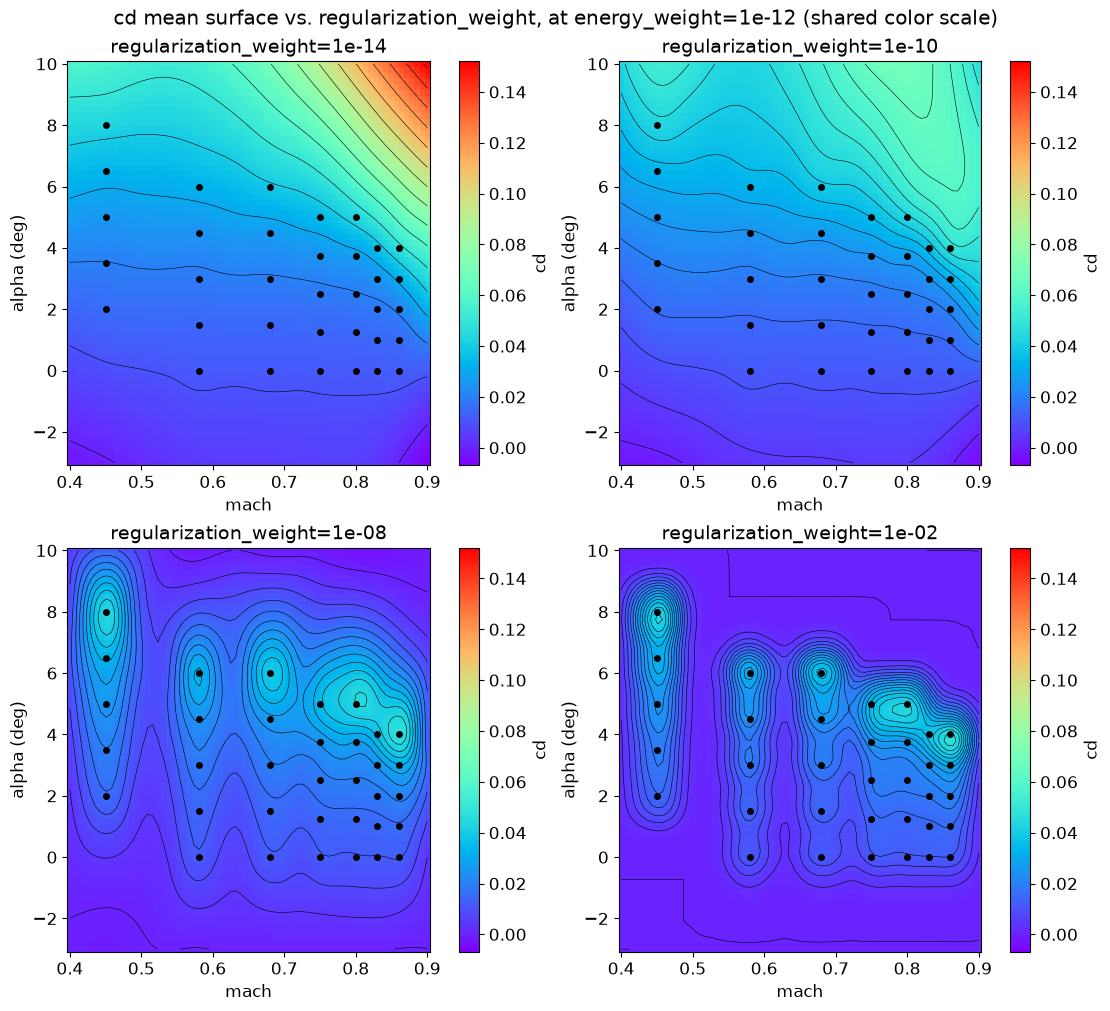

In [13]:
reg_mean_sweep = [1e-14, 1e-10, 1e-8, 1e-2]
GA_r, GM_r = np.meshgrid(np.linspace(-3.0, 10.0, 70), np.linspace(0.4, 0.90, 70), indexing="ij")
Xq_r = np.column_stack([np.radians(GA_r.ravel()), GM_r.ravel()])

mean_maps_r = {}
for reg_b in reg_mean_sweep:
    m_r = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
                 energy_weight=ew_risky, regularization_weight=reg_b,
                 solver="dense-lu", print_global=False)
    m_r.set_training_values(X, y)
    m_r.train()
    mean_maps_r[reg_b] = np.ravel(m_r.predict_values(Xq_r)).reshape(GA_r.shape)

vmin_r = min(Z.min() for Z in mean_maps_r.values())
vmax_r = max(Z.max() for Z in mean_maps_r.values())

fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, reg_b in zip(axs.flat, reg_mean_sweep):
    Z = mean_maps_r[reg_b]
    ax.plot(mach, alpha_deg, "ko", ms=4)
    ax.contour(GM_r, GA_r, Z, 15, colors="k", linewidths=0.4)
    pcm = ax.pcolormesh(GM_r, GA_r, Z, cmap="rainbow", vmin=vmin_r, vmax=vmax_r, shading="auto")
    fig.colorbar(pcm, ax=ax, label="cd")
    ax.set(xlabel="mach", ylabel="alpha (deg)", title=f"regularization_weight={reg_b:.0e}")
fig.suptitle(f"cd mean surface vs. regularization_weight, at energy_weight={ew_risky:.0e} (shared color scale)")
plt.show()


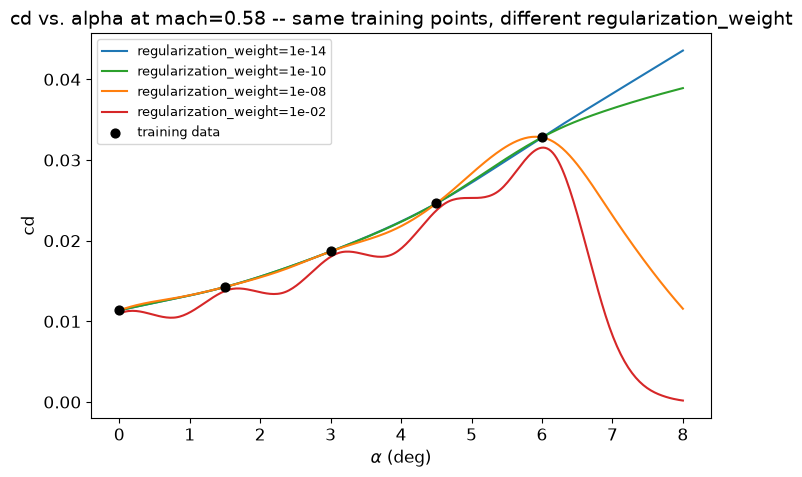

In [14]:
mach_gap = 0.58
alpha_sweep_r = np.linspace(0.0, 8.0, 300)
Xq_slice_r = np.column_stack([np.radians(alpha_sweep_r), np.full_like(alpha_sweep_r, mach_gap)])
near_r = np.abs(mach - mach_gap) < 1e-6

fig, ax = plt.subplots(figsize=(8, 5))
colors_r = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
for reg_b, color in zip(reg_mean_sweep, colors_r):
    m_r = RMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
                 energy_weight=ew_risky, regularization_weight=reg_b,
                 solver="dense-lu", print_global=False)
    m_r.set_training_values(X, y)
    m_r.train()
    ax.plot(alpha_sweep_r, m_r.predict_values(Xq_slice_r).ravel(), color=color,
             label=f"regularization_weight={reg_b:.0e}")
ax.scatter(alpha_deg[near_r], y[near_r], s=40, color="k", zorder=5, label="training data")
ax.set_xlabel(r"$\alpha$ (deg)"); ax.set_ylabel("cd")
ax.set_title(f"cd vs. alpha at mach={mach_gap} -- same training points, different regularization_weight")
ax.legend(fontsize=9)
plt.show()


**Confirmed: yes, substantially -- raising `regularization_weight` to
make the dual route safe measurably distorts RMTB's own mean surface,
even though it barely moves the training residual.** At the training
points themselves, the mean stays essentially pinned through
`regularization_weight=1e-6` (max shift `<2e-7`) and only starts to give
noticeably (`1.8e-3`) at `1e-2` -- consistent with `edf` finally dropping
from `35.0` to `33.1` there. But *between* training points, the surface
changes dramatically much earlier: the maximum shift within the dataset's
own `alpha`/`mach` range reaches `0.040` by `regularization_weight=1e-10`
and `0.096` by `1e-8` -- against `cd`'s own full range of only `0.036`.
**The maps show the mechanism directly, not just the number**: at
`regularization_weight=1e-14`/`1e-10` the surface extrapolates smoothly
beyond the data, rising toward the upper-right corner; by `1e-8` and
especially `1e-2` it has collapsed into isolated blobs centered on each
`mach` column's own data, reverting toward zero everywhere else -- even
in gaps *between* nearby `mach` levels, not just at the domain edges. The
slice at `mach=0.58` shows the same thing in 1-D: all four
`regularization_weight` values agree almost exactly *at* the five
training points, then visibly diverge between them, with
`regularization_weight=1e-2`'s curve dipping, wiggling, and finally
dropping toward zero past `alpha=6` (this `mach` level's own data stops
at `6.0`) while the smaller values keep extrapolating upward.

**Why, mechanically**: at `energy_weight=1e-12` the energy term itself
contributes almost nothing to `full_hess`, so `full_hess` is dominated by
`regularization_weight` times the identity. Raising `regularization_weight`
therefore does not just improve `full_hess`'s conditioning -- it adds a
real ridge penalty, shrinking the fitted coefficients of whichever
control points aren't tightly pinned by nearby data back toward zero. In
this `m=400\gg n=35` near-interpolation regime, most control points *are*
only loosely pinned, so this effect is large, not incidental.

**The practical conclusion**: the `regularization_weight` boost
validated above (Notebook 5's own mitigation, reused here) is a
legitimate way to make
`predict_variances_dual()` numerically safe, but it is **not** a drop-in
replacement for the original model's own mean fit -- at
`regularization_boost=1e-8`, it already reports `cd` values far from what
`energy_weight=1e-12`'s own `regularization_weight=1e-14` configuration
(SMT's own default, used throughout Test 1) predicts away from training
data. Any dual-route cross-check on this dataset should keep using the
*original*, unboosted model for the mean and for deciding what to trust
-- the boosted sibling `predict_variances_dual()` builds internally
should be treated as a variance-only probe, not a model in its own right.


## Conclusion

### What was tested and proved

This notebook reconstructed SMT's own published example for this
dataset, then pushed on the one hyperparameter choice that example makes
without comment: a very small `energy_weight`. Four things came out of
that, each checked directly rather than assumed.

First, `RMTBUQ`'s posterior-variance formula only works at certain basis
settings. Fitting with SMT's own exact hyperparameters reconstructs the
mean correctly -- the training residual is normal, and both outputs look
like the published plots. But `RMTBUQ`'s own internal bookkeeping, which
the variance formula depends on, silently breaks: `predict_variances()`
returns an implied uncertainty of about `29000` at a training point, on a
target that only ranges from `0.01` to `0.05`. Nothing raises an error.
Isolated directly, the cause is `order` and `approx_order` (SMT's own
defaults, left unset in its example) -- not the solver. Switching only
those two settings, and keeping SMT's own `num_ctrl_pts` and
`energy_weight`, gives a full, working reconstruction with real
uncertainty bands (Test 1a, Test 1b).

Second, that same `energy_weight` is genuinely risky by this project's
own numerical-safety standard, not just in theory. The relevant
conditioning number reaches `6.87e10` -- nearly three orders of magnitude
past the `1e8` line this project treats as safe, and millions of times
worse than this project's own synthetic test cases. It does not even
move in a predictable way as `energy_weight` changes. And yet, at the
training points specifically, the fitted values and their uncertainty
are still trustworthy -- because this setting pushes RMTB into (near-)
exact interpolation, where a separate, provable identity guarantees the
result is correct regardless of how bad the conditioning number looks
(Test 2).

Third, RMTB has two different ways to compute uncertainty -- a default
"weight" route and an optional "dual" route -- and the dual route has a
failure mode the usual safety check does not catch. A standard
conditioning check can say the dual route's system is safe to invert,
while a separate quantity inside the same formula is enormous, causing
two huge numbers to be subtracted to get a tiny one, losing precision
along the way. This project's own implementation still lands within a
fraction of a percent of the right answer, because it solves the system
directly instead of forming a matrix inverse -- a less careful
implementation of the identical formula was off by more than `10x`
(Test 3).

Fourth, and worth remembering on its own: the standard fix for that
dual-route risk -- raising `regularization_weight` -- is not free. It does
fix the conditioning, but it also measurably changes RMTB's own mean
prediction away from the training data, in some cases quite a lot, as the
2-D comparison above shows directly. It is a reasonable tool for
sanity-checking the uncertainty formula, but it should not be used as a
"better" or "safer" version of the model's actual prediction (Test 3).

A fifth, narrower finding -- a mismatch in how two different pieces of
code estimate the noise level, which only shows up in this same extreme
near-interpolation regime -- turned out to be about an internal
validation tool rather than about `RMTBUQ` itself, so it was moved into a
unit test instead of staying in this notebook.

### Recommendation

`RMTBUQ` works as intended -- its mean prediction and its uncertainty are
both trustworthy -- as long as it is used the way this project has
validated it: `order=4`, `approx_order=2`, and a direct (`dense-lu`)
solver. These are not stylistic choices; they are what makes the
bookkeeping the variance formula depends on actually hold. Changing them,
even to settings SMT itself treats as ordinary defaults, can silently
break the uncertainty output while leaving the mean prediction looking
completely normal. There is no warning when this happens, so it is worth
checking explicitly rather than assuming it is fine.

Within that validated configuration, `energy_weight` is the main lever,
and how it should be set depends on the data. On dense, well-covered
data, a small `energy_weight` (closer to exact interpolation) is safe and
gives sharper, more locally-responsive uncertainty. On sparse or
unevenly scattered real-world data -- the kind this notebook used --
pushing `energy_weight` that low can make the underlying system
extremely ill-conditioned. That is not automatically disqualifying:
values *at* the training points stay reliable even then, protected by
the same interpolation identity found here. But values *between*
training points deserve more scepticism the sparser and more irregular
the data gets, and it is worth checking the conditioning number directly
rather than assuming a setting that worked on one dataset will be equally
safe on another.

The dual route should be treated as an occasional cross-check, not a
routine substitute for the default. It is useful for confirming the main
uncertainty number is correct, but it has its own extra risk the standard
conditioning check does not catch, and the usual fix for that risk
(raising `regularization_weight`) changes the mean prediction, not just
the uncertainty. If it is used, its mean output should be compared back
against the original model before being trusted for anything beyond that
one check.

In short: trust `RMTBUQ` at its validated basis settings; treat very
small `energy_weight` values on sparse, real-world data as something to
verify rather than assume; and keep the dual route and any
conditioning-related adjustments scoped to checking the uncertainty
formula, not to replacing the model itself. This closes this project's
*correctness* validation sequence -- performance, on this and larger
datasets, is the next and final notebook's job.
